# جلسهٔ ۱ — تور عمیق: این ماشین‌ها واقعاً چه‌کار می‌کنند؟

*نت‌بوکِ معلم. هر سلول را زنده اجرا کن؛ دانش‌آموز قبل از هر «رونمایی» حدس می‌زند.*

امروز دو ماشین ساختی: **ماشینِ حیوانات** (در نمایش اول) و **ماشینِ تایتانیک** (کشتیِ تو).
امشب جعبهٔ هر دو را باز می‌کنیم و می‌بینیم:
از کجا «معلوم» است، کجا اشتباه می‌کند — و همین سه خط تا کجا می‌رود.

> **قانونِ بازی:** در هر ایست، اول حدس بزن؛ بعد اجرا کن. تور ده ایست دارد و کمتر از نیم‌ساعت.


## ایست ۰ — ابزارها را دوباره روی میز بگذاریم

همان دادهٔ تایتانیک و همان `X`، `y` و مدلی که در کلاس ساختی.


In [1]:
# COURSE SETUP — same imports as the session notebook, plus a rule-printer.
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# the same Titanic data and the same X, y from class (local file first, URL as fallback)
for _src in ("assets/titanic.csv", "../assets/titanic.csv",
             "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"):
    try:
        titanic = pd.read_csv(_src)
        break
    except Exception:
        continue
titanic = titanic.rename(columns=str.lower)
titanic = titanic[["survived", "pclass", "sex", "age", "fare", "embarked"]].dropna()

X = titanic[["pclass", "age", "fare"]].copy()
X["is_female"] = (titanic["sex"] == "female").astype(int)
y = titanic["survived"]

model = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X, y)
print(f"ready: {len(titanic)} passengers, and the same 3-line model from class.")


ready: 712 passengers, and the same 3-line model from class.


---

# پردهٔ ۱ — جعبه را باز کن

سه خطی که نوشتی، یک «قاعده» ساخت. حالا داخلش را می‌بینیم: ماشین دقیقاً چه چیزی یاد گرفت؟


## ایست ۱ — جعبهٔ کوچک: ماشینِ حیوانات

ماشینِ حیوانات فقط ۸ سطر دید و یک خط کشید. حالا داخل جعبهٔ آن نگاه کن.

**قبل از اجرا حدس بزن:** ماشینِ یک‌سؤالی چند سؤال پرسید — یک؟ دو؟ پنج؟


In [2]:
# stop 1 - open the small box: the animal machine
print("--- stop 1 - what the animal machine wrote itself ---")

animals = pd.DataFrame({
    "weight": [4.5, 3.0, 6.0, 5.0, 22, 32, 28, 38],
    "ear_length": [5, 7, 4, 6, 9, 12, 11, 13],
    "label": ["cat", "cat", "cat", "cat", "dog", "dog", "dog", "dog"],
}, index=["persian", "siamese", "garfield", "chartreux",
          "bulldog", "german", "golden", "doberman"])
A = animals[["weight", "ear_length"]]
b = animals["label"]

animal_model = DecisionTreeClassifier(max_depth=1, random_state=42).fit(A, b)
print("the whole machine is this one question it found by itself:")
print(export_text(animal_model, feature_names=list(A.columns)))
print("no human wrote that rule. it came out of 8 examples.")


--- stop 1 - what the animal machine wrote itself ---
the whole machine is this one question it found by itself:
|--- weight <= 14.00
|   |--- class: cat
|--- weight >  14.00
|   |--- class: dog

no human wrote that rule. it came out of 8 examples.


## ایست ۲ — جعبهٔ بزرگ: ماشینِ تایتانیک

همان سه خط، این بار روی ۷۱۲ زندگی. ماشین قاعده‌هایش را خودش نوشت.

**حدس بزن:** به کدام سرنخ بیشتر اعتماد کرد — کلاس؟ سن؟ کرایه؟ جنسیت؟


In [3]:
# stop 2 - open the big box: your Titanic machine
print("--- stop 2 - the rules your machine wrote from 712 lives ---")
print(export_text(model, feature_names=list(X.columns)))

print("how much it trusted each clue (its own numbers):")
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.to_string())
print("\nnobody typed 'women first'. the machine found it alone.")


--- stop 2 - the rules your machine wrote from 712 lives ---
|--- is_female <= 0.50
|   |--- age <= 6.50
|   |   |--- pclass <= 2.50
|   |   |   |--- class: 1
|   |   |--- pclass >  2.50
|   |   |   |--- class: 0
|   |--- age >  6.50
|   |   |--- pclass <= 1.50
|   |   |   |--- class: 0
|   |   |--- pclass >  1.50
|   |   |   |--- class: 0
|--- is_female >  0.50
|   |--- pclass <= 2.50
|   |   |--- age <= 2.50
|   |   |   |--- class: 0
|   |   |--- age >  2.50
|   |   |   |--- class: 1
|   |--- pclass >  2.50
|   |   |--- fare <= 20.80
|   |   |   |--- class: 1
|   |   |--- fare >  20.80
|   |   |   |--- class: 0

how much it trusted each clue (its own numbers):
is_female    0.617026
pclass       0.270188
age          0.072318
fare         0.040468

nobody typed 'women first'. the machine found it alone.


## ایست ۳ — حدس‌زن، نه داننده

ماشین هیچ‌وقت کتاب تاریخ نخوانده، از کوه یخ نشنیده، و نمی‌داند «۲۰۰ سالگی» یعنی چه.
مسافرانِ عجیب به آن بده و ببین چقدر مطمئن جواب می‌دهد.

**حدس بزن:** آیا جایی می‌گوید «نمی‌دانم»؟


In [4]:
# stop 3 - a guesser, not a knower
print("--- stop 3 - it never says 'I don't know' ---")
strange = pd.DataFrame([
    {"pclass": 1, "age": 200, "fare": 0,    "is_female": 1},
    {"pclass": 3, "age": 0.1, "fare": 999,  "is_female": 0},
    {"pclass": 1, "age": 30,  "fare": 1000, "is_female": 0},
], index=["200-year-old lady", "very rich baby", "first-class man"])

for name, p in zip(strange.index, model.predict(strange)):
    print(f"  {name:18} -> {'survives' if p else 'does not survive'}")
print("\nevery answer came out confident. there is no 'I am not sure' button.")


--- stop 3 - it never says 'I don't know' ---
  200-year-old lady  -> survives
  very rich baby     -> does not survive
  first-class man    -> does not survive

every answer came out confident. there is no 'I am not sure' button.


## ایست ۴ — ماشین، آینهٔ داده‌هایش

اگر تاریخ جورِ دیگری بود، ماشین هم طور دیگری «می‌دانست».
همین سه خط را فقط روی دادهٔ مردها آموزش بده.

**حدس بزن:** حالا دربارهٔ یک زنِ کلاس‌اول چه می‌گوید؟


In [5]:
# stop 4 - the machine is a mirror of its data
print("--- stop 4 - change the examples, change the mirror ---")
men = titanic[titanic["sex"] == "male"]
X_men = men[["pclass", "age", "fare"]].copy()
X_men["is_female"] = (men["sex"] == "female").astype(int)
model_men = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_men, men["survived"])

lady = pd.DataFrame([{"pclass": 1, "age": 30, "fare": 80, "is_female": 1}])
print("a first-class woman, machine trained on ALL passengers:",
      "survives" if model.predict(lady)[0] else "does not survive")
print("the same woman, machine trained on ONLY men:      ",
      "survives" if model_men.predict(lady)[0] else "does not survive")
print("\nthe machine has no opinion of its own - it mirrors whatever examples it was shown.")


--- stop 4 - change the examples, change the mirror ---
a first-class woman, machine trained on ALL passengers: survives
the same woman, machine trained on ONLY men:       does not survive

the machine has no opinion of its own - it mirrors whatever examples it was shown.


---

# پردهٔ ۲ — همین سه خط، هر دنیایی

ماشین به تایتانیک چسبیده نیست. داده را عوض کن؛ همان سه خط هر چیزی را یاد می‌گیرد.


## ایست ۵ — یک دستور، هزار سؤال

همان سه خط، یک دنیای تازه: «اگر این‌قدر درس بخوانم، قبول می‌شوم؟»

**حدس بزن:** ۶ ساعت درس، خوابِ بد — قبول می‌شود؟


In [6]:
# stop 5 - the same three lines, a brand-new world
print("--- stop 5 - one recipe, many questions ---")
study = pd.DataFrame({
    "hours_studied": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "slept_well":    [0, 0, 1, 0, 1, 1, 0, 1, 1, 1],
    "passed":        ["no", "no", "no", "no", "yes", "yes", "yes", "yes", "yes", "yes"],
})
study_model = DecisionTreeClassifier(max_depth=2, random_state=42)
study_model.fit(study[["hours_studied", "slept_well"]], study["passed"])

new_student = pd.DataFrame([{"hours_studied": 6, "slept_well": 0}])
print("6 hours studied, slept badly ->", study_model.predict(new_student)[0])
print("\nnot one line of code changed. only the data did.")


--- stop 5 - one recipe, many questions ---
6 hours studied, slept badly -> yes

not one line of code changed. only the data did.


## ایست ۶ — همین سه خط می‌تواند «ببیند»

برای کامپیوتر، عکس فقط یک مشت عدد است. یک تصویر کوچک را نشانش بده.

**حدس بزن:** می‌تواند رقمِ دست‌نویس را درست بخواند؟


--- stop 6 - images are just numbers ---
trained on 1347 tiny pictures (each one 8x8 pixels)
accuracy on pictures it never saw: 86%


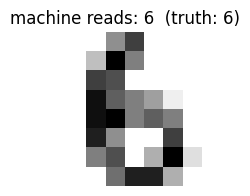

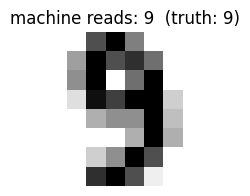

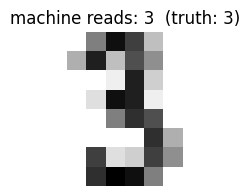

same three lines. this time they learned to see.


In [7]:
# stop 6 - the same recipe can SEE
print("--- stop 6 - images are just numbers ---")
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()   # built-in: tiny 8x8 handwritten digits, no download
X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target, random_state=42)

eye = DecisionTreeClassifier(max_depth=12, random_state=42).fit(X_train, y_train)
print(f"trained on {len(X_train)} tiny pictures (each one 8x8 pixels)")
print(f"accuracy on pictures it never saw: {eye.score(X_test, y_test):.0%}")

for i in range(3):
    guess = eye.predict(X_test[i:i + 1])[0]
    plt.figure(figsize=(2, 2))
    plt.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
    plt.axis("off")
    plt.title(f"machine reads: {guess}  (truth: {y_test[i]})")
    plt.show()
print("same three lines. this time they learned to see.")


## ایست ۷ — ... و می‌تواند «بخواند»

کلمه‌ها هم به عدد تبدیل می‌شوند؛ کافی است هر کلمه را بشماریم.

**حدس بزن:** پیامِ «free money now!» اسپم است یا نه؟


In [8]:
# stop 7 - the same recipe can READ
print("--- stop 7 - words become numbers ---")
words = ["free", "win", "cash", "now", "money", "gift", "school", "homework"]

messages = pd.DataFrame({
    "text": ["win a free prize now", "call now to win cash", "free money waiting for you",
             "free gift just for you", "see you at school tomorrow",
             "did you finish the homework", "let us play football after class",
             "mom says dinner is ready", "the exam moved to monday"],
    "label": ["spam", "spam", "spam", "spam",
              "not spam", "not spam", "not spam", "not spam", "not spam"],
})
for w in words:
    messages[w] = messages["text"].str.contains(w).astype(int)

reader = DecisionTreeClassifier(max_depth=3, random_state=42)
reader.fit(messages[words], messages["label"])

def count_words(text):
    return pd.DataFrame([{w: int(w in text) for w in words}])

for msg in ["free money now!", "see you at school tomorrow"]:
    print(f"  {msg:24} -> {reader.predict(count_words(msg))[0]}")
print("\nsame three lines. this time they learned to read.")


--- stop 7 - words become numbers ---
  free money now!          -> spam
  see you at school tomorrow -> not spam

same three lines. this time they learned to read.


---

# پردهٔ ۳ — چطور انتخاب می‌کند، و کجا می‌رویم

یک نگاهِ کوتاه به موتورِ انتخابِ سؤال — و بعد نقشهٔ راهِ دوره.


## ایست ۸ — ماشین سؤالِ اولش را چطور انتخاب کرد؟

ماشین سؤال‌ها را امتحان و «نمره» می‌کند.
نمرهٔ هر سؤال = غافلگیریِ قبل منهای غافلگیریِ بعد (بعداً اسمش را می‌گذاریم: بهرهٔ اطلاعاتی).

**حدس بزن:** کدام سؤال غافلگیری را بیشتر کم می‌کند — «زن هستی؟» یا «کرایه‌ات بالای ۳۰ بود؟»


In [9]:
# stop 8 - how the machine chose its first question
print("--- stop 8 - it measures surprise before choosing ---")
from collections import Counter

def surprise(labels):
    # a box's surprise level (entropy): 0 when pure, bigger when mixed.
    counts = np.array(list(Counter(labels).values()))
    p = counts / counts.sum()
    return float(-(p * np.log2(p)).sum())

def gain_of(mask):
    # how much surprise a yes/no question removes
    left, right = y[mask], y[~mask]
    after = (len(left) * surprise(left) + len(right) * surprise(right)) / len(y)
    return surprise(y) - after

print(f"surprise of the whole ship:      {surprise(y):.2f}")
print(f"gain of 'are you female?'        {gain_of(titanic['sex'] == 'female'):.2f}")
print(f"gain of 'was your fare over 30?' {gain_of(titanic['fare'] > 30):.2f}")
print("the biggest gain wins - and that is the machine's first question:")
print("  it actually picked:", X.columns[model.tree_.feature[0]])


--- stop 8 - it measures surprise before choosing ---
surprise of the whole ship:      0.97
gain of 'are you female?'        0.21


gain of 'was your fare over 30?' 0.04
the biggest gain wins - and that is the machine's first question:
  it actually picked: is_female


## ایست ۹ — جادهٔ پیشِ رو

همین یک درخت، شروعِ یک سفرِ بزرگ‌تر است.

**نگاه کن و بگو:** کدام ایست را بیشتر از همه می‌خواهی بسازی؟


--- stop 9 - the road ahead ---


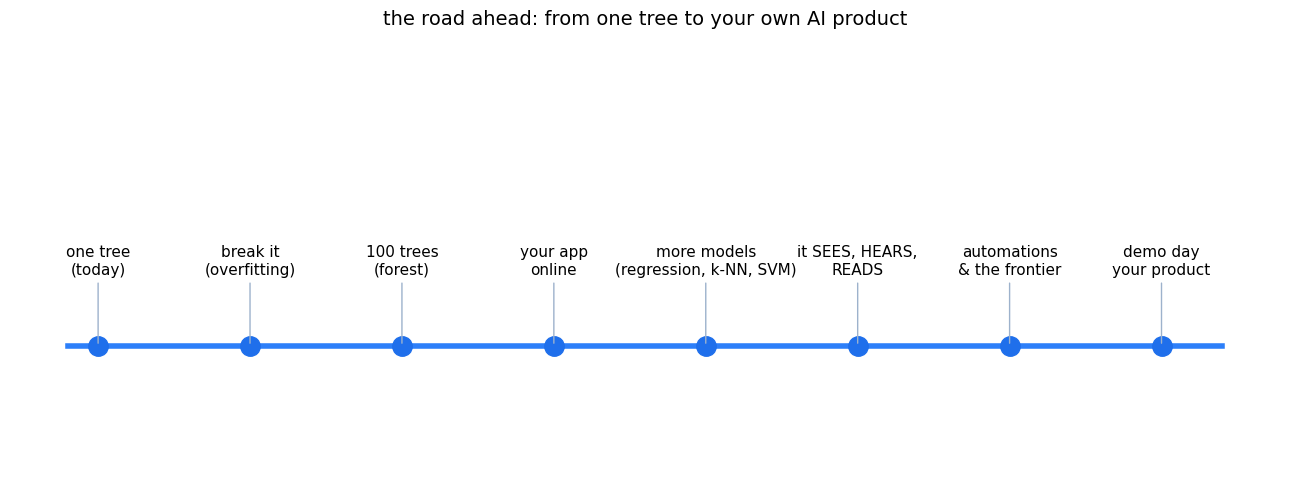

In [10]:
# stop 9 - the road ahead
print("--- stop 9 - the road ahead ---")
stops = [
    (0.5,  "one tree\n(today)"),
    (3.0,  "break it\n(overfitting)"),
    (5.5,  "100 trees\n(forest)"),
    (8.0,  "your app\nonline"),
    (10.5, "more models\n(regression, k-NN, SVM)"),
    (13.0, "it SEES, HEARS,\nREADS"),
    (15.5, "automations\n& the frontier"),
    (18.0, "demo day\nyour product"),
]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot([0, 19], [0, 0], "-", color="#2D7FF9", lw=4, zorder=1)
for x, label in stops:
    ax.plot([x], [0], "o", color="#1F6FEB", ms=14, zorder=2)
    ax.annotate(label, (x, 0), xytext=(x, 0.32), ha="center", fontsize=11,
                arrowprops=dict(arrowstyle="-", color="#9DB2CC"))
ax.set_ylim(-0.6, 1.4)
ax.axis("off")
ax.set_title("the road ahead: from one tree to your own AI product", fontsize=14)
plt.tight_layout()
plt.show()


## ایست ۱۰ — نوبت تو

مسافرِ خودت را بساز، **قبل از اجرا** حدس بزن، بعد ببین از کدام قاعدهٔ ماشین پیروی کرد.


In [11]:
# stop 10 - your move
print("--- stop 10 - your move ---")
mine = pd.DataFrame([{"pclass": 2, "age": 12, "fare": 26, "is_female": 1}])
verdict = model.predict(mine)[0]
print("your passenger ->", "survives" if verdict else "does not survive")
print("why? which rule of the machine did your passenger follow?")


--- stop 10 - your move ---
your passenger -> survives
why? which rule of the machine did your passenger follow?


---

## جمع‌بندی تور — و پردهٔ بعد

سه چیز دیدیم:

1. ماشین قواعدش را **خودش** می‌نویسد — از مثال‌ها.
2. ماشین نمی‌فهمد؛ **حدس** می‌زند، بی‌تردید، و **آینهٔ** داده‌هایش است.
3. همان سه خط، هر دنیایی را یاد می‌گیرد: بقای مسافر، قبولی در آزمون، خواندنِ تصویر، خواندنِ کلمه.

**جلسهٔ بعد:** خودت درخت را می‌خوانی، می‌کشی و حتی «جراحی»‌اش می‌کنی — گره، شاخه، برگ، و یک پیچِ تازه: عمق.

**و معمای اصلی باز می‌ماند:** ماشین سؤال‌های درختش را از کجا آورد؟ چه کسی گفت «اول جنسیت را بپرس»؟
جوابش پردهٔ بعدِ این داستان است — نه امروز.
